# 1. Import Semua Packages/Library yang Digunakan

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

# 2. Gathering Data

In [4]:
# Load the dataset
df = pd.read_csv('dataset.csv')
df.head()

,Tahun,Bulan,Jenis,room,bed,room_yesterday,room_in,room_out,wna_yesterday,wni_yesterday,...,RLMTA,MTNUS,TNUS,RLMTNUS,MTGAB,TGAB,RLMTGAB,TPTT,Bulan_Num,Tanggal
0,2022,Januari,Bintang,2325,3968,1647,1624,1647,0,3466,...,NaN,3434,3262,1.05,3434,3262,1.05,86.54,1,2022-01-01
1,2022,Januari,Bintang,30235,43472,17331,10575,10504,35,27557,...,2.06,27674,18258,1.52,27711,18276,1.52,63.74,1,2022-01-01
2,2022,Januari,Bintang,37318,53478,17891,14128,14127,8,28700,...,1.00,28631,22837,1.25,28639,22845,1.25,53.55,1,2022-01-01
3,2022,Januari,Bintang,5208,7316,2827,2391,2478,0,5118,...,NaN,4957,4280,1.16,4957,4280,1.16,67.76,1,2022-01-01
4,2022,Januari,Bintang,1054,1891,960,768,753,0,2420,...,NaN,2470,1536,1.61,2470,1536,1.61,130.62,1,2022-01-01


# 3. Assesing Data

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2477 entries, 0 to 2476
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Tahun                      2477 non-null   int64  
 1   Bulan                      2477 non-null   object 
 2   Jenis                      2477 non-null   object 
 3   room                       2477 non-null   int64  
 4   bed                        2477 non-null   int64  
 5   room_yesterday             2477 non-null   int64  
 6   room_in                    2477 non-null   int64  
 7   room_out                   2477 non-null   int64  
 8   wna_yesterday              2477 non-null   int64  
 9   wni_yesterday              2477 non-null   int64  
 10  wna_in/jml_tamu_asing      2477 non-null   int64  
 11  wni_in/jml_tamu_nusantara  2477 non-null   int64  
 12  wna_out                    2477 non-null   int64  
 13  wni_out                    2477 non-null   int64

In [6]:
# Cek jumlah duplikat
# Harus dicek manual di Spreadsheetnya
duplikat = df.duplicated()
print(f"Jumlah baris duplikat: {duplikat.sum()}")

# Tampilkan contoh duplikat
df[duplikat]

Jumlah baris duplikat: 11


,Tahun,Bulan,Jenis,room,bed,room_yesterday,room_in,room_out,wna_yesterday,wni_yesterday,...,RLMTA,MTNUS,TNUS,RLMTNUS,MTGAB,TGAB,RLMTGAB,TPTT,Bulan_Num,Tanggal
194,2023,Januari,Non Bintang,355,711,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,1,2023-01-01
198,2023,Januari,Non Bintang,355,711,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,1,2023-01-01
333,2023,Februari,Non Bintang,336,672,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,2,2023-02-01
747,2023,April,Non Bintang,396,792,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,4,2023-04-01
754,2023,April,Non Bintang,1397,2793,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,4,2023-04-01
1321,2023,Juli,Non Bintang,446,893,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,7,2023-07-01
1740,2023,September,Non Bintang,396,792,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,9,2023-09-01
1818,2023,Oktober,Non Bintang,1685,1685,1074,1074,1074,0,2179,...,NaN,2179,2179,1.0,2179,2179,1.0,129.0,10,2023-10-01
1956,2023,Oktober,Non Bintang,409,818,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,10,2023-10-01
2078,2023,November,Non Bintang,396,792,0,0,0,0,0,...,NaN,0,0,NaN,0,0,NaN,0.0,11,2023-11-01


In [7]:
#Memastikan Adanya Missing Value
df.isna().sum()

,0
Tahun,0
Bulan,0
Jenis,0
room,0
bed,0
room_yesterday,0
room_in,0
room_out,0
wna_yesterday,0
wni_yesterday,0


# 4. Cleaning Data dan EDA

## Menggabungkan TPK Gabungan (Tanggal dan TPK Historis)

In [8]:
# --- 1. Muat Kedua Data ---

# Data Historis
df_historical_raw = pd.read_csv('dataset.csv')

# --- 2. Konversi Kolom Tanggal ke Datetime ---
df_historical_raw['Tanggal'] = pd.to_datetime(df_historical_raw['Tanggal'])

# --- 3. Pilih Kolom Relevan & Beri Nama Jelas ---

# Untuk data historis, agregasi TPK per bulan/tanggal
# Karena data historis Anda tampaknya memiliki beberapa entri TPK per Tanggal, kita akan ambil rata-ratanya
tpk_ts_historical = df_historical_raw.dropna(subset=['TPK']).groupby('Tanggal')['TPK'].mean()
df_historical_clean = pd.DataFrame({
    'Tanggal': tpk_ts_historical.index,
    'TPK Historis': tpk_ts_historical.values
})

# Pastikan kedua DataFrame menggunakan 'Tanggal' sebagai indeks untuk penggabungan yang mudah
df_historical_clean = df_historical_clean.set_index('Tanggal')

# Menggunakan outer join agar semua tanggal (historis) disertakan
# dan nilai yang tidak ada diisi dengan NaN
combined_df = pd.concat([df_historical_clean], axis=1)
# Urutkan Data dan Reset Indeks (Opsional) ---
combined_df = combined_df.sort_index().reset_index()
combined_df = combined_df.rename(columns={'index': 'Tanggal'}) # Ganti nama kolom indeks kembali ke Tanggal

# --- 6. Simpan Data Gabungan ke CSV Baru ---
output_csv_filename = 'TPK_Tanggal_Historis.csv'
combined_df.to_csv(output_csv_filename, index=False)

print(f"Data gabungan berhasil dibuat dan disimpan sebagai '{output_csv_filename}'.")
print("\nLima baris pertama data gabungan:")
print(combined_df.head())
print("\nLima baris terakhir data gabungan:")
print(combined_df.tail())

Data gabungan berhasil dibuat dan disimpan sebagai 'TPK_Tanggal_Historis.csv'.

Lima baris pertama data gabungan:
     Tanggal  TPK Historis
0 2022-01-01     49.261111
1 2022-02-01     41.434444
2 2022-03-01     47.715556
3 2022-04-01     31.783333
4 2022-05-01     55.824444

Lima baris terakhir data gabungan:
      Tanggal  TPK Historis
36 2025-01-01        33.140
37 2025-02-01        30.270
38 2025-03-01        21.910
39 2025-04-01        34.795
40 2025-05-01        33.600


# EDA

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Tanggal       41 non-null     object 
 1   TPK Historis  41 non-null     float64
dtypes: float64(1), object(1)
memory usage: 788.0+ bytes
None

=== Statistik Deskriptif ===
       TPK Historis
count     41.000000
mean      35.724116
std        9.298067
min       21.910000
25%       27.920222
50%       33.600000
75%       41.434444
max       55.824444

=== Missing Values per Kolom ===
Tanggal         0
TPK Historis    0
dtype: int64


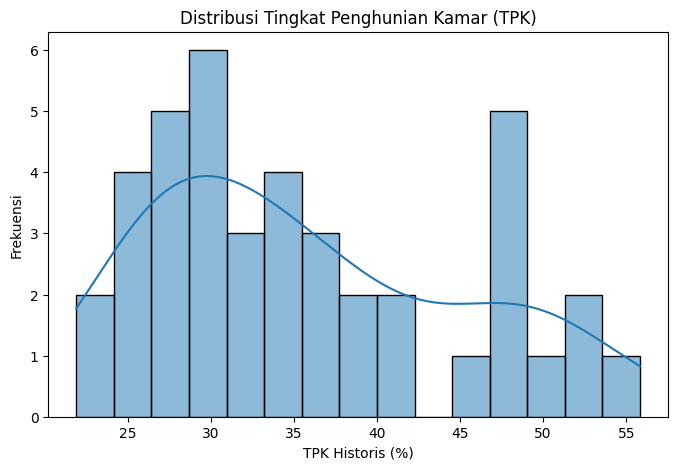

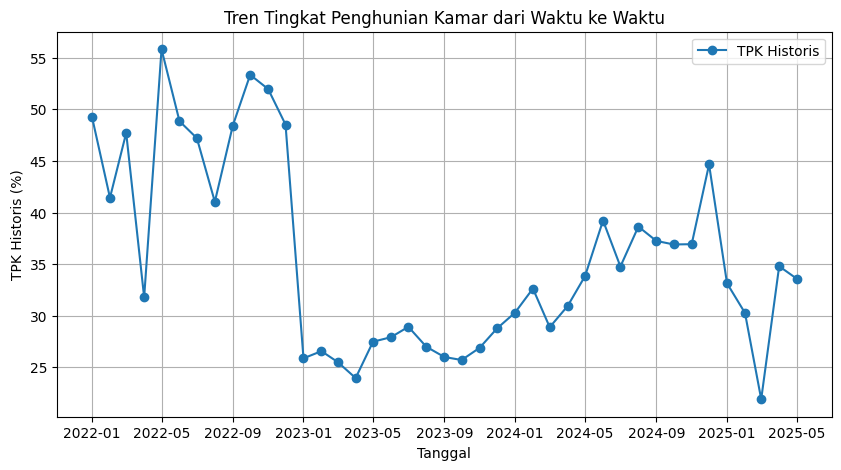

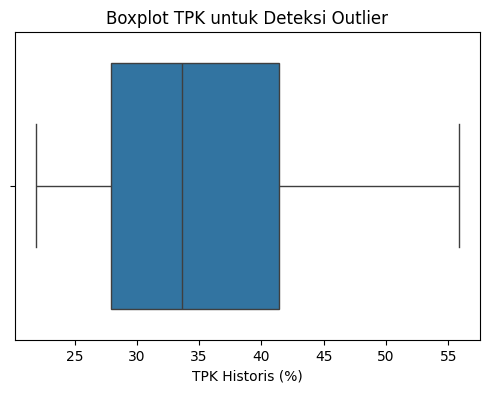

In [11]:
# ============================================================
# Exploratory Data Analysis (EDA) untuk Dataset TPK
# ============================================================

# --- 1. Muat Dataset (setelah cleaning) ---
df = pd.read_csv("TPK_Tanggal_Historis.csv")

# --- 2. Informasi dasar dataset ---
print("=== Informasi Dataset ===")
print(df.info())
print("\n=== Statistik Deskriptif ===")
print(df.describe())

# --- 3. Cek missing value ---
print("\n=== Missing Values per Kolom ===")
print(df.isnull().sum())

# --- 4. Distribusi data TPK Historis ---
plt.figure(figsize=(8, 5))
sns.histplot(df['TPK Historis'], kde=True, bins=15)
plt.title("Distribusi Tingkat Penghunian Kamar (TPK)")
plt.xlabel("TPK Historis (%)")
plt.ylabel("Frekuensi")
plt.show()

# --- 5. Visualisasi tren waktu (Time Series Plot) ---
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
plt.figure(figsize=(10, 5))
plt.plot(df['Tanggal'], df['TPK Historis'], marker='o', label='TPK Historis')
plt.title("Tren Tingkat Penghunian Kamar dari Waktu ke Waktu")
plt.xlabel("Tanggal")
plt.ylabel("TPK Historis (%)")
plt.grid(True)
plt.legend()
plt.show()

# --- 6. Boxplot untuk mendeteksi outlier ---
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['TPK Historis'])
plt.title("Boxplot TPK untuk Deteksi Outlier")
plt.xlabel("TPK Historis (%)")
plt.show()

# COBa coba


## Step 1: Universe of Discourse

In [7]:
# ==========================
# Step 1: Universe of Discourse
# ==========================

# 1. Muat dataset
df = pd.read_csv("TPK_Tanggal_Historis.csv")

# 2. Konversi kolom tanggal ke datetime dan jadikan index
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# 3. Ambil kolom target (misalnya 'TPK Historis')
data = df['TPK Historis'].values

# 4. Tentukan batas bawah & atas (min & max)
D_min = data.min()
D_max = data.max()

# 5. Tambahkan buffer 10% agar tidak terlalu ketat
buffer = (D_max - D_min) * 0.1
U_start = D_min - buffer
U_end = D_max + buffer

print("Nilai minimum data (D_min):", D_min)
print("Nilai maksimum data (D_max):", D_max)
print("Buffer tambahan:", buffer)
print("Universe of Discourse:", f"[{U_start:.2f}, {U_end:.2f}]")


Nilai minimum data (D_min): 21.91
Nilai maksimum data (D_max): 55.82444444444444
Buffer tambahan: 3.3914444444444443
Universe of Discourse: [18.52, 59.22]


## Step 2: Partitioning

In [8]:
n = 20
interval_length = (U_end - U_start) / n
intervals = []
for i in range(n):
    lower = U_start + i * interval_length
    upper = lower + interval_length
    intervals.append((lower, upper))

print(f"\nJumlah interval: {n}")
print(f"Panjang setiap interval: {interval_length:.3f}")

print("\nContoh 5 interval pertama:")
for i in range(5):
    print(f"A{i+1}: [{intervals[i][0]:.2f}, {intervals[i][1]:.2f}]")


Jumlah interval: 20
Panjang setiap interval: 2.035

Contoh 5 interval pertama:
A1: [18.52, 20.55]
A2: [20.55, 22.59]
A3: [22.59, 24.62]
A4: [24.62, 26.66]
A5: [26.66, 28.69]


## Step 3: Fuzzy Sets (Midpoints)

In [9]:
# ==========================
# Step 3: Fuzzy Sets (Midpoints)
# ==========================

# Hitung titik tengah (midpoint) dari setiap interval
fuzzy_sets = [np.mean(interval) for interval in intervals]

# Tampilkan hasilnya
print("Daftar Fuzzy Set (midpoint):")
for i, mid in enumerate(fuzzy_sets, start=1):
    print(f"A{i}: {mid:.2f}")


Daftar Fuzzy Set (midpoint):
A1: 19.54
A2: 21.57
A3: 23.61
A4: 25.64
A5: 27.68
A6: 29.71
A7: 31.75
A8: 33.78
A9: 35.81
A10: 37.85
A11: 39.88
A12: 41.92
A13: 43.95
A14: 45.99
A15: 48.02
A16: 50.06
A17: 52.09
A18: 54.13
A19: 56.16
A20: 58.20


## Step 4: Fuzzifikasi

In [10]:
# ==========================
# Step 4: Fuzzifikasi
# ==========================

def fuzzify(value, intervals):
    """
    Mengembalikan indeks interval (fuzzy set) yang sesuai untuk suatu nilai.
    """
    for i, (start, end) in enumerate(intervals):
        if start <= value <= end:
            return i  # kembalikan index interval
    # jika di luar range
    if value < intervals[0][0]:
        return 0
    if value > intervals[-1][1]:
        return len(intervals) - 1
    return None

# Terapkan fungsi fuzzify ke semua nilai data
fuzzified_data = [fuzzify(val, intervals) for val in data]

# Tampilkan hasil sebagian (misalnya 10 pertama)
print("Hasil fuzzifikasi (10 data pertama):")
for i, val in enumerate(fuzzified_data[:10]):
    print(f"Data ke-{i+1}: {data[i]:.2f} → A{val+1}")


Hasil fuzzifikasi (10 data pertama):
Data ke-1: 49.26 → A16
Data ke-2: 41.43 → A12
Data ke-3: 47.72 → A15
Data ke-4: 31.78 → A7
Data ke-5: 55.82 → A19
Data ke-6: 48.85 → A15
Data ke-7: 47.21 → A15
Data ke-8: 41.04 → A12
Data ke-9: 48.42 → A15
Data ke-10: 53.34 → A18


## Step 5: FLR & FLRG (Fuzzy Logical Relationships & Groups)

In [11]:
# ==========================
# Step 5: FLR & FLRG (Fuzzy Logical Relationships & Groups)
# ==========================

from collections import defaultdict
import numpy as np
import pandas as pd

# fuzzified_data = list indeks interval (0-based) hasil fuzzifikasi
# Misal: [5, 3, 5, 2, 6, 5, 4, 3, 5, 5, ...]
# Pastikan variable 'fuzzified_data' sudah ada dari langkah sebelumnya
n_intervals = len(intervals)  # misal 7

# 1) Buat FLR: mapping current_index -> list of next indices (bisa duplikat utk frekuensi)
flrs = defaultdict(list)
for i in range(len(fuzzified_data) - 1):
    cur = fuzzified_data[i]
    nxt = fuzzified_data[i + 1]
    flrs[cur].append(nxt)

# 2) Buat FLRG: mapping current_index -> UNIQUE set (sorted) dari next states
flrgs = {cur: sorted(set(nexts)) for cur, nexts in flrs.items()}

# 3) Hitung frekuensi transisi (transition count matrix)
transition_counts = np.zeros((n_intervals, n_intervals), dtype=int)
for cur, nexts in flrs.items():
    for nxt in nexts:
        transition_counts[cur, nxt] += 1

# 4) Buat transition probability matrix (opsional)
transition_probs = transition_counts.astype(float)
row_sums = transition_probs.sum(axis=1, keepdims=True)
# untuk baris yang sum = 0, biarkan 0 agar tidak terbagi nol
nonzero_rows = (row_sums[:,0] != 0)
transition_probs[nonzero_rows] = transition_probs[nonzero_rows] / row_sums[nonzero_rows]

# 5) Cetak FLRG (dengan nama A1..An) dan tabel frekuensi sederhana
print("=== FLRG (Fuzzy Logical Relationship Groups) ===")
for cur in range(n_intervals):
    group = flrgs.get(cur, [])
    group_names = [f"A{idx+1}" for idx in group]
    print(f"A{cur+1} -> {group_names if group_names else '— (tidak ada transisi)'}")

print("\n=== Transition Counts (baris = current, kolom = next) ===")
df_counts = pd.DataFrame(transition_counts,
                         index=[f"A{i+1}" for i in range(n_intervals)],
                         columns=[f"A{i+1}" for i in range(n_intervals)])
print(df_counts)

print("\n=== Transition Probabilities (baris -> next, sum tiap baris = 1 jika ada transisi) ===")
df_probs = pd.DataFrame(np.round(transition_probs, 3),
                        index=[f"A{i+1}" for i in range(n_intervals)],
                        columns=[f"A{i+1}" for i in range(n_intervals)])
print(df_probs)


=== FLRG (Fuzzy Logical Relationship Groups) ===
A1 -> — (tidak ada transisi)
A2 -> ['A8']
A3 -> ['A5']
A4 -> ['A3', 'A4', 'A5']
A5 -> ['A4', 'A5', 'A6']
A6 -> ['A2', 'A5', 'A6', 'A7']
A7 -> ['A6', 'A8', 'A19']
A8 -> ['A6', 'A8', 'A10', 'A11']
A9 -> — (tidak ada transisi)
A10 -> ['A10', 'A13']
A11 -> ['A8']
A12 -> ['A15']
A13 -> ['A8']
A14 -> — (tidak ada transisi)
A15 -> ['A4', 'A7', 'A12', 'A15', 'A18']
A16 -> ['A12']
A17 -> ['A15']
A18 -> ['A17']
A19 -> ['A15']
A20 -> — (tidak ada transisi)

=== Transition Counts (baris = current, kolom = next) ===
     A1  A2  A3  A4  A5  A6  A7  A8  A9  A10  A11  A12  A13  A14  A15  A16  \
A1    0   0   0   0   0   0   0   0   0    0    0    0    0    0    0    0   
A2    0   0   0   0   0   0   0   1   0    0    0    0    0    0    0    0   
A3    0   0   0   0   1   0   0   0   0    0    0    0    0    0    0    0   
A4    0   0   1   3   1   0   0   0   0    0    0    0    0    0    0    0   
A5    0   0   0   1   1   2   0   0   0    0    0   

In [12]:
# ==========================
# Step 6: Prediksi Menggunakan Model Chen
# ==========================

from sklearn.metrics import mean_squared_error # Import mean_squared_error

predictions = []

for i in range(len(fuzzified_data) - 1):
    current_state = fuzzified_data[i]

    # Let's refine the prediction logic based on FLRGs as calculated in Step 5.
    # If the current state has defined transitions, average the midpoints of the possible next states.
    if current_state in flrgs and flrgs[current_state]:
        possible_next_indices = flrgs[current_state]
        # Access fuzzy_sets using integer indices
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_indices]
        pred_value = np.mean(predicted_midpoints)
    else:
        # If no defined transition, predict the midpoint of the current fuzzy set
        pred_value = fuzzy_sets[current_state]

    predictions.append(pred_value)


# Because the prediction starts from the second data point (predicting data[1] from data[0]),
# the actual values for comparison start from the second data point.
actual = data[1:len(predictions)+1]


# Hitung error (MAE dan RMSE)
mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

print("=== Hasil Prediksi Model Chen ===")
print(f"Jumlah data yang diprediksi: {len(predictions)}")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

# Tampilkan 10 hasil pertama
print("\nContoh hasil prediksi (10 data pertama):")
for i in range(min(10, len(predictions))):
    print(f"Data ke-{i+1}: Aktual = {actual[i]:.2f}, Prediksi = {predictions[i]:.2f}")

=== Hasil Prediksi Model Chen ===
Jumlah data yang diprediksi: 40
MAE: 3.427
RMSE: 5.279

Contoh hasil prediksi (10 data pertama):
Data ke-1: Aktual = 41.43, Prediksi = 41.92
Data ke-2: Aktual = 47.72, Prediksi = 48.02
Data ke-3: Aktual = 31.78, Prediksi = 40.29
Data ke-4: Aktual = 55.82, Prediksi = 39.88
Data ke-5: Aktual = 48.85, Prediksi = 48.02
Data ke-6: Aktual = 47.21, Prediksi = 40.29
Data ke-7: Aktual = 41.04, Prediksi = 40.29
Data ke-8: Aktual = 48.42, Prediksi = 48.02
Data ke-9: Aktual = 53.34, Prediksi = 40.29
Data ke-10: Aktual = 51.97, Prediksi = 52.09


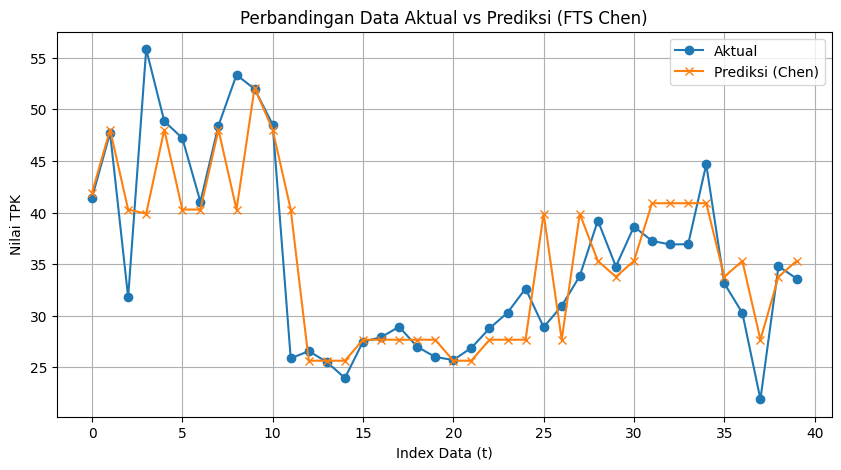

In [13]:
# ==========================
# Step 7: Visualisasi Prediksi vs Aktual
# ==========================
plt.figure(figsize=(10,5))
plt.plot(range(len(actual)), actual, label='Aktual', marker='o')
plt.plot(range(len(predictions)), predictions, label='Prediksi (Chen)', marker='x')
plt.title('Perbandingan Data Aktual vs Prediksi (FTS Chen)')
plt.xlabel('Index Data (t)')
plt.ylabel('Nilai TPK')
plt.legend()
plt.grid(True)
plt.show()


# COBA COBA LAGI

## Langkah 1. Muat Data

In [29]:
# ============================================================
# Langkah 1. Muat Data
# ============================================================

df = pd.read_csv("TPK_Tanggal_Historis.csv")
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

data = df['TPK Historis'].values
print(f"Jumlah data: {len(data)}")

Jumlah data: 41


## Langkah 2. Menentukan Semesta Pembicaraan (Universe of Discourse)

In [30]:
# ============================================================
# Langkah 2. Tentukan Semesta Pembicaraan (Universe of Discourse)
# ============================================================

D_min = np.min(data)
D_max = np.max(data)
buffer = (D_max - D_min) * 0.1  # buffer 10%
U_lower = D_min - buffer
U_upper = D_max + buffer

print(f"\nNilai minimum data (D_min): {D_min:.2f}")
print(f"Nilai maksimum data (D_max): {D_max:.2f}")
print(f"Buffer tambahan: {buffer:.2f}")
print(f"Universe of Discourse: [{U_lower:.2f}, {U_upper:.2f}]")
print(f"Range data: {D_max - D_min:.2f}")
print(f"Range Universe: {U_upper - U_lower:.2f} (10% lebih lebar dari data asli)")


Nilai minimum data (D_min): 21.91
Nilai maksimum data (D_max): 55.82
Buffer tambahan: 3.39
Universe of Discourse: [18.52, 59.22]
Range data: 33.91
Range Universe: 40.70 (10% lebih lebar dari data asli)


## Langkah 3. Membagi Semesta Sesuai dengan Interval

In [38]:
# ============================================================
# Langkah 3. Bagi Menjadi 13 Interval
# ============================================================

n = 13
interval_length = (U_upper - U_lower) / n
intervals = []
for i in range(n):
    lower = U_lower + i * interval_length
    # Adjust upper bound slightly to avoid floating point issues
    upper = U_lower + (i + 1) * interval_length
    intervals.append((lower, upper))

print(f"\nJumlah interval: {n}")
print(f"Panjang setiap interval: {interval_length:.3f}")

print("\nContoh 5 interval pertama:")
interval_labels = [f"A{i+1}" for i in range(n)]
interval_df = pd.DataFrame(intervals, columns=["Batas Bawah", "Batas Atas"], index=interval_labels)
display(interval_df)



Jumlah interval: 13
Panjang setiap interval: 3.131

Contoh 5 interval pertama:


,Batas Bawah,Batas Atas
A1,18.518556,21.649120
A2,21.649120,24.779684
A3,24.779684,27.910248
A4,27.910248,31.040812
A5,31.040812,34.171376
A6,34.171376,37.301940
A7,37.301940,40.432504
A8,40.432504,43.563068
A9,43.563068,46.693632
A10,46.693632,49.824197


## Langkah 4. Menentukan Fuzzy Set (Midpoint)

In [39]:
# ============================================================
# Langkah 4. Tentukan Fuzzy Set (Midpoint)
# ============================================================
# Nilai tengah digunakan untuk representasi numerik setiap fuzzy set
# Misal: A1 mewakili interval [x1, x2] dengan midpoint m1

fuzzy_sets = {f"A{i+1}": np.mean(intervals[i]) for i in range(n)}

print("\nDaftar Fuzzy Set (midpoint):")

fuzzy_df = pd.DataFrame({
    "Fuzzy Set": list(fuzzy_sets.keys()),
    "Midpoint": list(fuzzy_sets.values())
})
display(fuzzy_df)



Daftar Fuzzy Set (midpoint):


,Fuzzy Set,Midpoint
0,A1,20.083838
1,A2,23.214402
2,A3,26.344966
3,A4,29.475530
4,A5,32.606094
5,A6,35.736658
6,A7,38.867222
7,A8,41.997786
8,A9,45.128350
9,A10,48.258915


## Langkah 5. Fuzzifikasi

In [50]:
# ============================================================
# Langkah 5. Fuzzifikasi (versi dengan tabel output)
# ============================================================
def fuzzify(value, intervals):
    """
    Menentukan indeks interval (fuzzy set) yang sesuai untuk suatu nilai.
    Mengembalikan indeks berbasis 0 (0-based index).
    Handles values outside the defined intervals by returning the index of the closest interval.
    """
    for i, (lower, upper) in enumerate(intervals):
        # If the value is within the interval (inclusive lower, exclusive upper)
        if lower <= value < upper:
            return i
        # For the last interval, include the upper bound
        if i == len(intervals) - 1 and value == upper:
            return i
    # Handle values outside the universe of discourse by mapping to the closest interval
    if value < intervals[0][0]:
        return 0
    if value > intervals[-1][1]:
        return len(intervals) - 1
    return None  # Should not happen if universe is well-defined and values are within or mapped to closest interval


# --- Apply fuzzification to all data ---
fuzzy_data = [fuzzify(x, intervals) for x in data]

# --- Create fuzzification results table ---
fuzzy_table = pd.DataFrame({
    "Tanggal": df.index[:len(fuzzy_data)],
    "Nilai Asli": data,
    "Himpunan Fuzzy": [f"A{i+1}" if i is not None else "N/A" for i in fuzzy_data]})
# --- Display results ---
print("\n=== Hasil Fuzzifikasi (10 data pertama) ===")
display(fuzzy_table)


=== Hasil Fuzzifikasi (10 data pertama) ===


,Tanggal,Nilai Asli,Himpunan Fuzzy
0,2022-01-01,49.261111,A10
1,2022-02-01,41.434444,A8
2,2022-03-01,47.715556,A10
3,2022-04-01,31.783333,A5
4,2022-05-01,55.824444,A12
5,2022-06-01,48.851111,A10
6,2022-07-01,47.205556,A10
7,2022-08-01,41.042222,A8
8,2022-09-01,48.420000,A10
9,2022-10-01,53.343333,A12


## Langkah 6: Fuzzy Logical Relationship (FLR)

In [51]:
# ==========================
# Langkah 6: Fuzzy Logical Relationship (FLR)
# ==========================
from collections import defaultdict

# Gunakan hasil fuzzifikasi dari langkah sebelumnya
try:
    fuzzified_data = fuzzy_data
except NameError:
    print("⚠️ Warning: 'fuzzy_data' tidak ditemukan. Pastikan menjalankan Langkah 5 terlebih dahulu.")

n_intervals = len(intervals)

# 1) Buat FLR: mapping current_index -> list of next indicesS
flrs = defaultdict(list)
for i in range(len(fuzzified_data) - 1):
    cur = fuzzified_data[i]
    nxt = fuzzified_data[i + 1]
    # Add checks to ensure cur and nxt are valid indices
    if isinstance(cur, int) and isinstance(nxt, int) and 0 <= cur < n_intervals and 0 <= nxt < n_intervals:
        flrs[cur].append(nxt)
    else:
        print(f"Warning: Skipping invalid fuzzy index transition at index {i}: {cur} -> {nxt}")


# 2) Buat tabel FLR untuk ditampilkan
flr_list = []
for i in range(len(fuzzified_data) - 1):
    # Ensure fuzzy_data[i] and fuzzy_data[i+1] are valid indices before using them
    if isinstance(fuzzified_data[i], int) and isinstance(fuzzified_data[i+1], int):
        flr_list.append({
            "No": i + 1,
            "Waktu_t": f"t{i+1}",
            "Fuzzy_Sekarang": f"A{fuzzified_data[i]+1}",
            "Waktu_t+1": f"t{i+2}",
            "Fuzzy_Berikutnya": f"A{fuzzified_data[i+1]+1}",
            "FLR": f"A{fuzzified_data[i]+1} → A{fuzzified_data[i+1]+1}"
        })
    else:
         print(f"Warning: Skipping FLR table entry due to invalid fuzzy index at index {i}")


df_flr = pd.DataFrame(flr_list)
print("=== Tabel Fuzzy Logical Relationship (FLR) ===")
display(df_flr)  # tampilkan 15 baris pertama

# Jumlah total FLR
print(f"\nTotal FLR yang terbentuk: {len(df_flr)} hubungan logis.")

=== Tabel Fuzzy Logical Relationship (FLR) ===


,No,Waktu_t,Fuzzy_Sekarang,Waktu_t+1,Fuzzy_Berikutnya,FLR
0,1,t1,A10,t2,A8,A10 → A8
1,2,t2,A8,t3,A10,A8 → A10
2,3,t3,A10,t4,A5,A10 → A5
3,4,t4,A5,t5,A12,A5 → A12
4,5,t5,A12,t6,A10,A12 → A10
5,6,t6,A10,t7,A10,A10 → A10
6,7,t7,A10,t8,A8,A10 → A8
7,8,t8,A8,t9,A10,A8 → A10
8,9,t9,A10,t10,A12,A10 → A12
9,10,t10,A12,t11,A11,A12 → A11



Total FLR yang terbentuk: 40 hubungan logis.


## Langkah 7: Fuzzy Logical Relationship Group (FLRG)


=== Tabel Fuzzy Logical Relationship Groups (FLRG) ===


,No,Fuzzy_Sekarang,Fuzzy_Berikutnya,Keterangan
0,1,A1,—,Stabil (tidak ada transisi)
1,2,A2,"A3, A6",2 kemungkinan transisi
2,3,A3,"A2, A3, A4",3 kemungkinan transisi
3,4,A4,"A2, A3, A4, A5",4 kemungkinan transisi
4,5,A5,"A4, A7, A12",3 kemungkinan transisi
5,6,A6,"A5, A6, A7, A9",4 kemungkinan transisi
6,7,A7,A6,1 kemungkinan transisi
7,8,A8,A10,1 kemungkinan transisi
8,9,A9,A5,1 kemungkinan transisi
9,10,A10,"A3, A5, A8, A10, A12",5 kemungkinan transisi


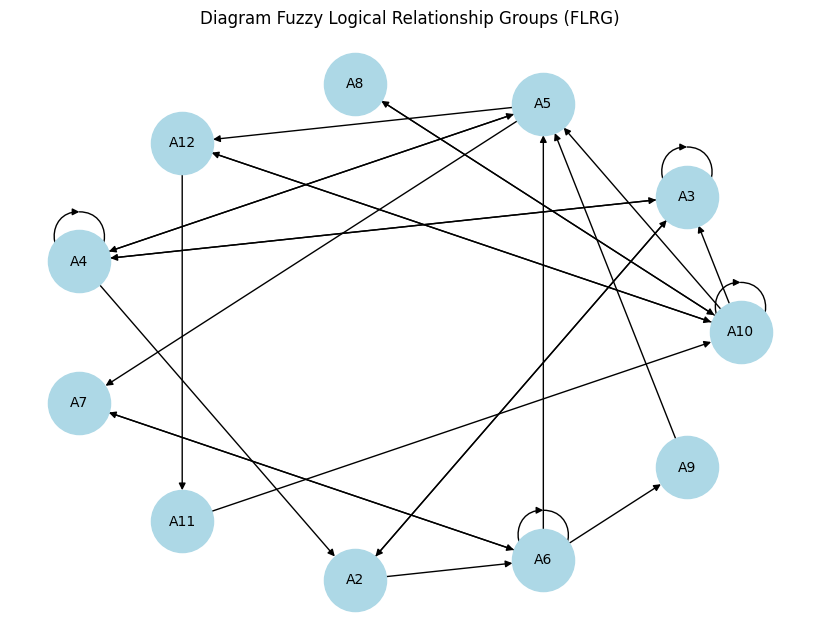


=== Transition Counts (row = current, column = next) ===


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13
A1,0,0,0,0,0,0,0,0,0,0,0,0,0
A2,0,0,1,0,0,1,0,0,0,0,0,0,0
A3,0,1,5,2,0,0,0,0,0,0,0,0,0
A4,0,1,1,3,2,0,0,0,0,0,0,0,0
A5,0,0,0,2,0,0,1,0,0,0,0,1,0
A6,0,0,0,0,1,2,1,0,1,0,0,0,0
A7,0,0,0,0,0,2,0,0,0,0,0,0,0
A8,0,0,0,0,0,0,0,0,0,2,0,0,0
A9,0,0,0,0,1,0,0,0,0,0,0,0,0
A10,0,0,1,0,1,0,0,2,0,1,0,1,0



=== Transition Probabilities (row -> next, sum of each row = 1 if there are transitions) ===


,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13
A1,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0
A2,0.0,0.00,0.50,0.00,0.00,0.5,0.00,0.00,0.0,0.00,0.0,0.00,0.0
A3,0.0,0.12,0.62,0.25,0.00,0.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0
A4,0.0,0.14,0.14,0.43,0.29,0.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0
A5,0.0,0.00,0.00,0.50,0.00,0.0,0.25,0.00,0.0,0.00,0.0,0.25,0.0
A6,0.0,0.00,0.00,0.00,0.20,0.4,0.20,0.00,0.2,0.00,0.0,0.00,0.0
A7,0.0,0.00,0.00,0.00,0.00,1.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0
A8,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.0,1.00,0.0,0.00,0.0
A9,0.0,0.00,0.00,0.00,1.00,0.0,0.00,0.00,0.0,0.00,0.0,0.00,0.0
A10,0.0,0.00,0.17,0.00,0.17,0.0,0.00,0.33,0.0,0.17,0.0,0.17,0.0


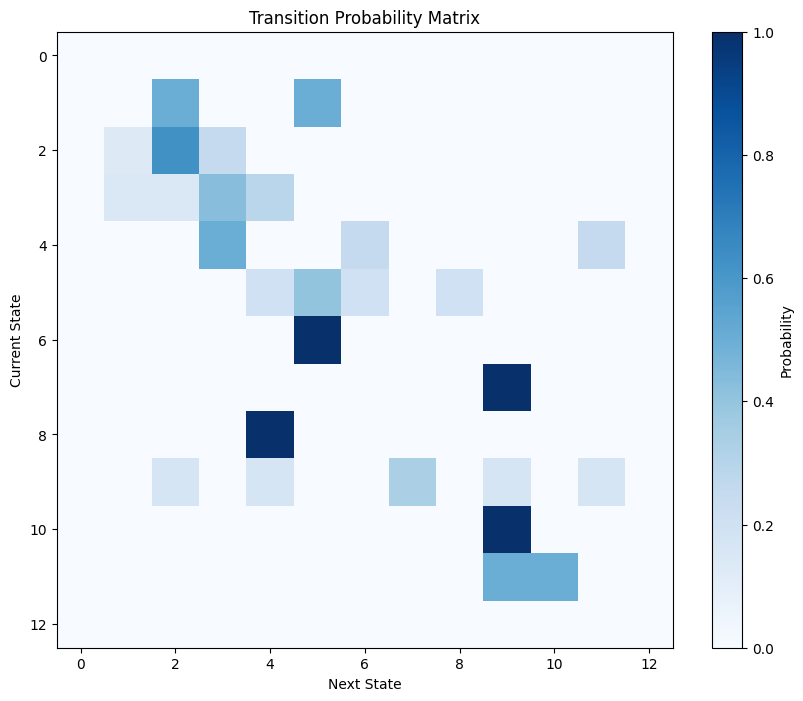

In [48]:
# ============================================================
# Langkah 7: Fuzzy Logical Relationship Group (FLRG)
# ============================================================

import networkx as nx
import matplotlib.pyplot as plt

# Use flrs generated in the previous step
try:
    flrs
except NameError:
    print("⚠️ Warning: 'flrs' not found. Please run Step 6 first.")
    flrs = {} # Initialize to avoid errors

# 1) Create FLRG: mapping current_index -> UNIQUE set (sorted) of next states
flrgs = {cur: sorted(list(set(nexts))) for cur, nexts in flrs.items()}


# ============================================================
# 1) Buat tabel FLRG untuk laporan
# ============================================================
flrg_list = []

for cur in range(n_intervals):
    # Get the list of next fuzzy sets (consequent)
    consequents = flrgs.get(cur, [])
    consequents_names = [f"A{idx+1}" for idx in consequents if isinstance(idx, int)] # Ensure index is integer before using

    flrg_list.append({
        "No": cur + 1,
        "Fuzzy_Sekarang": f"A{cur+1}",
        "Fuzzy_Berikutnya": ", ".join(consequents_names) if consequents_names else "—",
        "Keterangan": "Stabil (tidak ada transisi)" if not consequents_names
                      else f"{len(consequents_names)} kemungkinan transisi"
    })

# Display the FLRG table
df_flrg = pd.DataFrame(flrg_list)
print("\n=== Tabel Fuzzy Logical Relationship Groups (FLRG) ===")
display(df_flrg)

# ============================================================
# 2) Visualisasi FLRG dengan Network Graph
# ============================================================

G = nx.DiGraph()

# Add edges based on FLRG
for cur, nexts in flrgs.items():
    # Ensure cur is a valid integer index before using
    if isinstance(cur, int):
        for nxt in nexts:
            # Ensure nxt is a valid integer index before using
            if isinstance(nxt, int):
                 G.add_edge(f"A{cur+1}", f"A{nxt+1}")


# Draw the graph
plt.figure(figsize=(8, 6)) # Increased figure size for better visibility
pos = nx.circular_layout(G) # Use circular layout
nx.draw(G, pos, with_labels=True, node_color="lightblue",
        node_size=2000, font_size=10, arrows=True)
plt.title("Diagram Fuzzy Logical Relationship Groups (FLRG)")
plt.show()

# ============================================================
# 3) Hitung Transition Count & Probability Matrix
# ============================================================

# Initialize the transition count matrix
transition_counts = np.zeros((n_intervals, n_intervals), dtype=int)

# Calculate transition counts between fuzzy sets
# Use flrs directly as it contains counts
for cur, nexts in flrs.items():
    # Ensure cur is a valid integer index before using
    if isinstance(cur, int):
        for nxt in nexts:
             # Ensure nxt is a valid integer index before using
             if isinstance(nxt, int):
                transition_counts[cur, nxt] += 1


# Convert to transition probabilities
transition_probs = transition_counts.astype(float)
row_sums = transition_probs.sum(axis=1, keepdims=True)
# Avoid division by zero for rows with no transitions
nonzero_rows = (row_sums[:, 0] != 0)
transition_probs[nonzero_rows] = transition_probs[nonzero_rows] / row_sums[nonzero_rows]

# ============================================================
# 4) Tampilkan Hasil dalam Bentuk Tabel
# ============================================================

print("\n=== Transition Counts (row = current, column = next) ===")
df_counts = pd.DataFrame(transition_counts,
                         index=[f"A{i+1}" for i in range(n_intervals)],
                         columns=[f"A{i+1}" for i in range(n_intervals)])
display(df_counts)

print("\n=== Transition Probabilities (row -> next, sum of each row = 1 if there are transitions) ===")
df_probs = pd.DataFrame(np.round(transition_probs, 2),
                        index=[f"A{i+1}" for i in range(n_intervals)],
                        columns=[f"A{i+1}" for i in range(n_intervals)])
display(df_probs)

# ============================================================
# 5) Visualisasi Matriks Probabilitas Transisi
# ============================================================

plt.figure(figsize=(10, 8))
plt.imshow(transition_probs, cmap='Blues', interpolation='nearest')
plt.title('Transition Probability Matrix')
plt.xlabel('Next State')
plt.ylabel('Current State')
plt.colorbar(label='Probability')
plt.show()

## Langkah 8. Defuzzifikasi dan Prediksi (Training)

In [49]:
# ============================================================
# Langkah 8. Defuzzifikasi dan Prediksi (Training)
# ============================================================

# Store predictions in a dictionary keyed by the index of the data point being predicted
predictions_dict = {}

# Iterate through the data to generate predictions
for i in range(len(fuzzy_data) - 1):
    current_index = fuzzy_data[i] # Get the integer index for the current data point
    next_index = fuzzy_data[i+1] # Get the integer index for the next data point (which we are predicting)

    # Ensure the current index is a valid integer before proceeding
    if not isinstance(current_index, int):
        continue # Skip if the current fuzzy data is not a valid integer index

    current_key = f"A{current_index + 1}" # Construct the string key for the current fuzzy set

    pred = np.nan # Default prediction to NaN

    # Check if the current fuzzy state has defined relationships
    if current_index in flrgs:
        next_indices = flrgs[current_index] # Get the list of possible next integer indices

        valid_midpoints = []
        for idx in next_indices:
            key = f"A{idx + 1}"
            if key in fuzzy_sets:
                valid_midpoints.append(fuzzy_sets[key])

        if valid_midpoints:
            pred = np.mean(valid_midpoints)
        elif current_key in fuzzy_sets:
             # Fallback: if no valid next states have corresponding midpoints, use the current state's midpoint
             pred = fuzzy_sets[current_key]

    elif current_key in fuzzy_sets:
        # If no relationship found in FLRGs, but current fuzzy set exists, use its midpoint
        pred = fuzzy_sets[current_key]

    # Store the generated prediction (even if NaN for now) associated with the index it predicts
    predictions_dict[i + 1] = pred # Predicts data[i+1] from data[i]

# Align predictions with actual values for evaluation
actual = []
predictions = []
valid_indices = []

# Start from the second data point as the first can't be predicted
for i in range(1, len(data)):
    actual_value = data[i]
    predicted_value = predictions_dict.get(i, np.nan) # Get prediction using index, default to NaN if not found

    # Only include pairs where both actual and predicted values are valid numbers
    if not np.isnan(actual_value) and not np.isnan(predicted_value):
        actual.append(actual_value)
        predictions.append(predicted_value)
        valid_indices.append(df.index[i]) # Store the corresponding date for plotting/results

# Ensure actual and predictions are numpy arrays for evaluation
actual = np.array(actual)
predictions = np.array(predictions)

# ============================================================
# Langkah 8b. Prediksi Bulan Berikutnya
# ============================================================

last_fuzzy_index = fuzzy_data[-1] # Get the last integer index from the original fuzzy_data list

# Check if the last fuzzy index is a valid integer before proceeding
next_pred = np.nan # Default to NaN in case of invalid last fuzzy index
if isinstance(last_fuzzy_index, int) and 0 <= last_fuzzy_index < len(intervals):
    last_fuzzy_key = f"A{last_fuzzy_index + 1}" # Construct the string key

    if last_fuzzy_index in flrgs: # Check if the last integer index exists in flrgs
        next_indices = flrgs[last_fuzzy_index] # Get the list of next integer indices
        # Construct string keys for next fuzzy sets and get midpoints
        valid_midpoints = []
        for idx in next_indices:
             key = f"A{idx + 1}"
             if key in fuzzy_sets:
                 valid_midpoints.append(fuzzy_sets[key])

        if valid_midpoints: # Ensure there are valid midpoints to average
             next_pred = np.mean(valid_midpoints)
        elif last_fuzzy_key in fuzzy_sets:
             # Fallback if no valid next states but the last fuzzy set is valid
             next_pred = fuzzy_sets[last_fuzzy_key]

    elif last_fuzzy_key in fuzzy_sets:
        # If no relationship, predict the midpoint of the last fuzzy set
        next_pred = fuzzy_sets[last_fuzzy_key]

print(f"\nPrediksi untuk bulan berikutnya (Juni): {next_pred:.2f}")

# Create DataFrame for defuzzified and predicted results for evaluation
results_df = pd.DataFrame({
    'Tanggal': valid_indices,
    'Actual': actual,
    'Predicted': predictions
})

print("\n=== Hasil Defuzzifikasi dan Prediksi (Data untuk Evaluasi) ===")
display(results_df.head())
print(f"Jumlah data untuk evaluasi: {len(results_df)}")


Prediksi untuk bulan berikutnya (Juni): 40.95

=== Hasil Defuzzifikasi dan Prediksi (Data untuk Evaluasi) ===


,Tanggal,Actual,Predicted
0,2022-02-01,41.434444,40.745561
1,2022-03-01,47.715556,48.258915
2,2022-04-01,31.783333,40.745561
3,2022-05-01,55.824444,40.954265
4,2022-06-01,48.851111,49.824197


Jumlah data untuk evaluasi: 40


## Langkah 9. Evaluasi Model

In [44]:
# ============================================================
# Langkah 9. Evaluasi Model
# ============================================================

mae = mean_absolute_error(actual, predictions)
mape = mean_absolute_percentage_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

print("\n=== Hasil Evaluasi Model Chen (n=13) ===")
print(f"Jumlah data yang diprediksi: {len(predictions)}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.4f}")
print(f"RMSE: {rmse:.4f}")

print("\nContoh hasil prediksi (10 data pertama):")
for i in range(10):
    print(f"Data ke-{i+1}: Aktual = {actual[i]:.2f}, Prediksi = {predictions[i]:.2f}")


=== Hasil Evaluasi Model Chen (n=13) ===
Jumlah data yang diprediksi: 40
MAE: 3.6138
MAPE: 0.1069
RMSE: 5.5107

Contoh hasil prediksi (10 data pertama):
Data ke-1: Aktual = 41.43, Prediksi = 40.75
Data ke-2: Aktual = 47.72, Prediksi = 48.26
Data ke-3: Aktual = 31.78, Prediksi = 40.75
Data ke-4: Aktual = 55.82, Prediksi = 40.95
Data ke-5: Aktual = 48.85, Prediksi = 49.82
Data ke-6: Aktual = 47.21, Prediksi = 40.75
Data ke-7: Aktual = 41.04, Prediksi = 40.75
Data ke-8: Aktual = 48.42, Prediksi = 48.26
Data ke-9: Aktual = 53.34, Prediksi = 40.75
Data ke-10: Aktual = 51.97, Prediksi = 49.82


## Langkah 10. Visualisasi Hasil

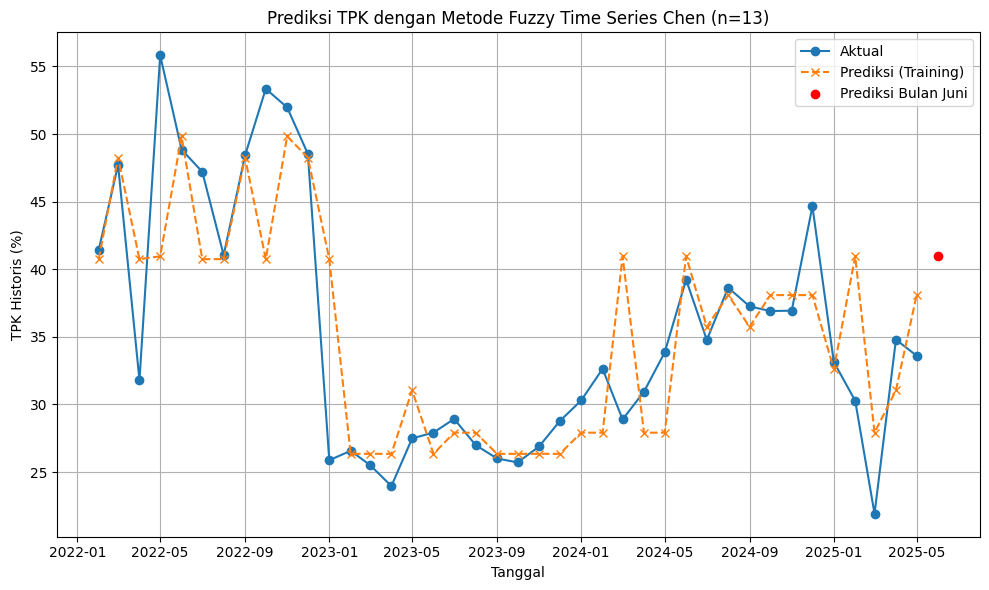

In [45]:
# ============================================================
# Langkah 10. Visualisasi Hasil (Versi Koreksi)
# ============================================================

plt.figure(figsize=(10, 6))

# Plot data aktual & prediksi (training period)
plt.plot(results_df['Tanggal'], results_df['Actual'], label='Aktual', marker='o')
plt.plot(results_df['Tanggal'], results_df['Predicted'], label='Prediksi (Training)', linestyle='--', marker='x')

# Titik prediksi bulan berikutnya
next_date = df.index[-1] + pd.DateOffset(months=1)
plt.scatter(next_date, next_pred, color='red', label='Prediksi Bulan Juni', zorder=5)

plt.title("Prediksi TPK dengan Metode Fuzzy Time Series Chen (n=13)")
plt.xlabel("Tanggal")
plt.ylabel("TPK Historis (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



## Langkah 11. Simpan Hasil ke CSV

In [24]:
# ============================================================
# Langkah 11. Simpan Hasil ke CSV
# ============================================================

# Gabungkan hasil historis
result_df = pd.DataFrame({
    "Tanggal": df.index[1:].strftime("%Y-%m-%d"),
    "Aktual": actual.copy(),
    "Prediksi": predictions.copy()
})

# Bulatkan hasil agar rapi
result_df["Aktual"] = result_df["Aktual"].round(2)
result_df["Prediksi"] = result_df["Prediksi"].round(2)

# Tambahkan baris prediksi bulan berikutnya
next_row = pd.DataFrame({
    "Tanggal": [next_date.strftime("%Y-%m-%d")],
    "Aktual": [np.nan],
    "Prediksi": [round(next_pred, 2)]
})

# Gabungkan dan simpan
final_result = pd.concat([result_df, next_row], ignore_index=True)
final_result.to_csv("Hasil_Prediksi_FTS_Chen_n13.csv", index=False)

print("\n✅ Hasil prediksi telah disimpan ke file: 'Hasil_Prediksi_FTS_Chen_n13.csv'")
print(f"Jumlah data tersimpan: {len(final_result)} baris")
print("5 data terakhir hasil prediksi:")
display(final_result.tail())



✅ Hasil prediksi telah disimpan ke file: 'Hasil_Prediksi_FTS_Chen_n13.csv'
Jumlah data tersimpan: 41 baris
5 data terakhir hasil prediksi:


,Tanggal,Aktual,Prediksi
36,2025-02-01,30.27,32.61
37,2025-03-01,21.91,29.48
38,2025-04-01,34.80,42.00
39,2025-05-01,33.60,32.61
40,2025-06-01,NaN,32.61


# COBA COBA SEMUA LANGKAH

Jumlah data: 41

Nilai minimum data (D_min): 21.91
Nilai maksimum data (D_max): 55.82
Buffer tambahan: 3.39
Universe of Discourse: [18.52, 59.22]

Jumlah interval: 13
Panjang setiap interval: 3.131

Contoh 5 interval pertama:
A1: [18.52, 21.65]
A2: [21.65, 24.78]
A3: [24.78, 27.91]
A4: [27.91, 31.04]
A5: [31.04, 34.17]

Daftar Fuzzy Set (midpoint):
A1: 20.08
A2: 23.21
A3: 26.34
A4: 29.48
A5: 32.61
A6: 35.74
A7: 38.87
A8: 42.00
A9: 45.13
A10: 48.26
A11: 51.39
A12: 54.52
A13: 57.65

=== Hasil Fuzzifikasi (10 data pertama) ===
Data ke-1: 49.26 → A10
Data ke-2: 41.43 → A8
Data ke-3: 47.72 → A10
Data ke-4: 31.78 → A5
Data ke-5: 55.82 → A12
Data ke-6: 48.85 → A10
Data ke-7: 47.21 → A10
Data ke-8: 41.04 → A8
Data ke-9: 48.42 → A10
Data ke-10: 53.34 → A12

=== Relasi Fuzzy (contoh 5) ===
A10 → ['A3', 'A5', 'A12', 'A10', 'A8']
A8 → ['A10']
A5 → ['A12', 'A4', 'A7']
A12 → ['A10', 'A11']
A11 → ['A10']

Prediksi untuk bulan berikutnya: 40.95

=== Hasil Evaluasi Model Chen (n=13) ===
Jumlah data yan

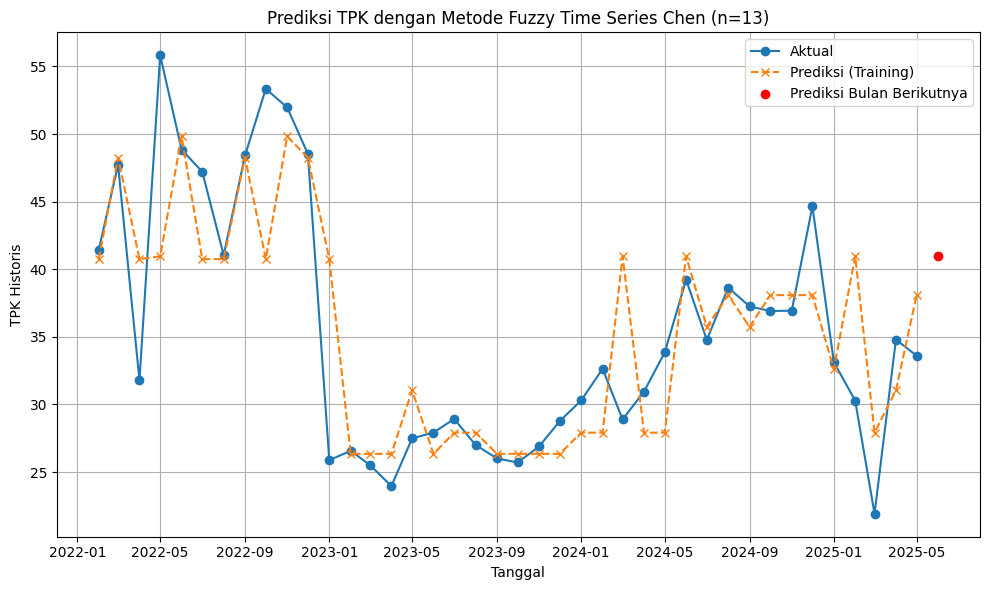


✅ Hasil prediksi telah disimpan ke file: 'Hasil_Prediksi_FTS_Chen_n13.csv'


In [25]:
# ============================================================
# Langkah 1. Muat Data
# ============================================================

df = pd.read_csv("TPK_Tanggal_Historis.csv")
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

data = df['TPK Historis'].values
print(f"Jumlah data: {len(data)}")

# ============================================================
# Langkah 2. Tentukan Semesta Pembicaraan (Universe of Discourse)
# ============================================================

D_min = np.min(data)
D_max = np.max(data)
buffer = (D_max - D_min) * 0.1  # buffer 10%
U_lower = D_min - buffer
U_upper = D_max + buffer

print(f"\nNilai minimum data (D_min): {D_min:.2f}")
print(f"Nilai maksimum data (D_max): {D_max:.2f}")
print(f"Buffer tambahan: {buffer:.2f}")
print(f"Universe of Discourse: [{U_lower:.2f}, {U_upper:.2f}]")

# ============================================================
# Langkah 3. Bagi Menjadi 13 Interval
# ============================================================

n = 13
interval_length = (U_upper - U_lower) / n
intervals = []
for i in range(n):
    lower = U_lower + i * interval_length
    upper = lower + interval_length
    intervals.append((lower, upper))

print(f"\nJumlah interval: {n}")
print(f"Panjang setiap interval: {interval_length:.3f}")

print("\nContoh 5 interval pertama:")
for i in range(5):
    print(f"A{i+1}: [{intervals[i][0]:.2f}, {intervals[i][1]:.2f}]")

# ============================================================
# Langkah 4. Tentukan Fuzzy Set (Midpoint)
# ============================================================

fuzzy_sets = {f"A{i+1}": np.mean(intervals[i]) for i in range(n)}

print("\nDaftar Fuzzy Set (midpoint):")
for k, v in fuzzy_sets.items():
    print(f"{k}: {v:.2f}")

# ============================================================
# Langkah 5. Fuzzifikasi
# ============================================================

def fuzzify(value):
    for i, (lower, upper) in enumerate(intervals):
        if lower <= value <= upper:
            return f"A{i+1}"
    return None

fuzzy_data = [fuzzify(x) for x in data]

print("\n=== Hasil Fuzzifikasi (10 data pertama) ===")
for i in range(10):
    print(f"Data ke-{i+1}: {data[i]:.2f} → {fuzzy_data[i]}")

# ============================================================
# Langkah 6. Bentuk Relasi Fuzzy (Model Chen)
# ============================================================

rules = {}
for i in range(len(fuzzy_data) - 1):
    left = fuzzy_data[i]
    right = fuzzy_data[i + 1]
    if left not in rules:
        rules[left] = set()
    rules[left].add(right)

print("\n=== Relasi Fuzzy (contoh 5) ===")
for i, (k, v) in enumerate(rules.items()):
    if i >= 5:
        break
    print(f"{k} → {list(v)}")

# ============================================================
# Langkah 7. Defuzzifikasi dan Prediksi (Training)
# ============================================================

predictions = []
for i in range(len(fuzzy_data) - 1):
    current = fuzzy_data[i]
    if current in rules:
        next_sets = list(rules[current])
        midpoints = [fuzzy_sets[s] for s in next_sets]
        pred = np.mean(midpoints)
    else:
        pred = fuzzy_sets[current]
    predictions.append(pred)

actual = data[1:]

# ============================================================
# Langkah 7b. Prediksi Bulan Berikutnya
# ============================================================

last_fuzzy = fuzzy_data[-1]

if last_fuzzy in rules:
    next_sets = list(rules[last_fuzzy])
    midpoints = [fuzzy_sets[s] for s in next_sets]
    next_pred = np.mean(midpoints)
else:
    next_pred = fuzzy_sets[last_fuzzy]

print(f"\nPrediksi untuk bulan berikutnya: {next_pred:.2f}")

# ============================================================
# Langkah 8. Evaluasi Model
# ============================================================

mae = mean_absolute_error(actual, predictions)
mape = mean_absolute_percentage_error(actual, predictions)

print("\n=== Hasil Evaluasi Model Chen (n=13) ===")
print(f"Jumlah data yang diprediksi: {len(predictions)}")
print(f"MAE: {mae:.4f}")
print(f"MAPE: {mape:.4f}")

print("\nContoh hasil prediksi (10 data pertama):")
for i in range(10):
    print(f"Data ke-{i+1}: Aktual = {actual[i]:.2f}, Prediksi = {predictions[i]:.2f}")

# ============================================================
# Langkah 9. Visualisasi Hasil
# ============================================================

plt.figure(figsize=(10, 6))
plt.plot(df.index[1:], actual, label='Aktual', marker='o')
plt.plot(df.index[1:], predictions, label='Prediksi (Training)', linestyle='--', marker='x')

# Titik prediksi bulan berikutnya
next_date = df.index[-1] + pd.DateOffset(months=1)
plt.scatter(next_date, next_pred, color='red', label='Prediksi Bulan Berikutnya', zorder=5)

plt.title("Prediksi TPK dengan Metode Fuzzy Time Series Chen (n=13)")
plt.xlabel("Tanggal")
plt.ylabel("TPK Historis")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# Langkah 10. Simpan Hasil ke CSV
# ============================================================

# Gabungkan hasil historis
result_df = pd.DataFrame({
    "Tanggal": df.index[1:].strftime("%Y-%m-%d"),
    "Aktual": actual,
    "Prediksi": predictions
})

# Tambahkan baris prediksi bulan berikutnya
next_row = pd.DataFrame({
    "Tanggal": [next_date.strftime("%Y-%m-%d")],
    "Aktual": [np.nan],
    "Prediksi": [next_pred]
})

# Gabungkan dan simpan
final_result = pd.concat([result_df, next_row], ignore_index=True)
final_result.to_csv("Hasil_Prediksi_FTS_Chen_n13.csv", index=False)

print("\n✅ Hasil prediksi telah disimpan ke file: 'Hasil_Prediksi_FTS_Chen_n13.csv'")


# 5. TPK dan Prediksi Metode Fuzzy Time Series (2022-2025)

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load dataset
df = pd.read_csv("TPK_Tanggal_Historis.csv")

# Convert kolom waktu ke datetime dan set index
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Ambil data target
data = df['TPK Historis'].values

# ==========================
# Step 1: Universe of Discourse
# ==========================
D_min, D_max = data.min(), data.max()
buffer = (D_max - D_min) * 0.1
U_start, U_end = D_min - buffer, D_max + buffer

# Step 2: Partition
num_intervals = 1400
interval_length = (U_end - U_start) / num_intervals
intervals = [(U_start + i * interval_length, U_start + (i + 1) * interval_length) for i in range(num_intervals)]

# Step 3: Fuzzy sets (midpoints)
fuzzy_sets = [np.mean(interval) for interval in intervals]

# Step 4: Fuzzify
def fuzzify(value, intervals, num_intervals_arg):
  for i, (start, end) in enumerate(intervals):
    if start <= value <= end:
      return i
    if value < intervals[0][0]:
      return 0
    if value > intervals[-1][1]:
      return num_intervals_arg - 1
    return None

fuzzified_data = [fuzzify(val, intervals, num_intervals) for val in data]


# Step 5 & 6: FLRs & FLRGs
flrs = {}
for i in range(len(fuzzified_data) - 1):
  cur, nxt = fuzzified_data[i], fuzzified_data[i + 1]
  flrs.setdefault(cur, []).append(nxt)
flrgs = {cur: sorted(set(nexts)) for cur, nexts in flrs.items()}

# Step 7: Forecast in-sample
predictions = []
for i in range(len(fuzzified_data) - 1):
  cur_state = fuzzified_data[i]
  if cur_state in flrgs:
    possible_next = flrgs[cur_state]
    pred_midpoints = [fuzzy_sets[idx] for idx in possible_next]
    predictions.append(np.mean(pred_midpoints))
  else:
    predictions.append(fuzzy_sets[cur_state])

# ==========================
# Evaluasi akurasi
# ==========================
actual_values = data[1:]
predicted_values = np.array(predictions)
min_len = min(len(actual_values), len(predicted_values))
actual_values_eval = actual_values[:min_len]
predicted_values_eval = predicted_values[:min_len]
mean_actual = np.mean(actual_values_eval)
mae = mean_absolute_error(actual_values_eval, predicted_values_eval)
rmse = np.sqrt(mean_squared_error(actual_values_eval, predicted_values_eval))
me = np.mean(actual_values_eval - predicted_values_eval)

# Skala persen
mae_pct = (mae / mean_actual) * 100
rmse_pct = (rmse / mean_actual) * 100
me_pct = (me / mean_actual) * 100
mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / np.where(actual_values_eval != 0, actual_values_eval, 1e-8))) * 100
smape = np.mean(np.abs(actual_values_eval - predicted_values_eval) / (np.abs(actual_values_eval) + np.abs(predicted_values_eval))) * 100


# ==========================
# Prediksi bulan depan (out-of-sample)
# ==========================
last_state = fuzzified_data[-1]
if last_state in flrgs:
  possible_next = flrgs[last_state]
  pred_midpoints = [fuzzy_sets[idx] for idx in possible_next]
  next_prediction = np.mean(pred_midpoints)
else: next_prediction = fuzzy_sets[last_state]
next_date = df.index[-1] + pd.DateOffset(months=1)


# ==========================
# Output hasil
# ==========================
print("\n=== Evaluasi Akurasi Model ===")
print(f"Mean Absolute Error (MAE): {mae_pct:.2f}%")
print(f"Root Mean Squared Error (RMSE): {rmse_pct:.2f}%")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Symmetric Mean Absolute Percentage Error (SMAPE): {smape:.2f}%")
print(f"Mean Error (ME): {me_pct:.2f}%")
print("\n=== Prediksi Bulan Berikutnya ===")
print(f"Prediksi TPK untuk {next_date.strftime('%B %Y')}: {next_prediction:.2f}%")

# ==========================
# Plot hasil
# ==========================
plt.figure(figsize=(12, 6))
plt.plot(df.index[1:min_len+1], actual_values_eval, label='Aktual', color='blue')
plt.plot(df.index[1:min_len+1], predicted_values_eval, label='Prediksi', color='red', linestyle='--')
plt.scatter(next_date, next_prediction, color='green', s=100, label='Prediksi Bulan Depan')
plt.axvline(next_date, color='green', linestyle=':', alpha=0.6)
plt.title('Peramalan Tingkat Penghunian Kamar (TPK) dengan Fuzzy Time Series')
plt.xlabel('Tanggal')
plt.ylabel('TPK (%)')
plt.legend()
plt.grid(True)
plt.show()

TypeError: list indices must be integers or slices, not NoneType

# 6. Prediksi 12 bulan kedepan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the dataset
df = pd.read_csv('TPK_Tanggal_Historis.csv')

# Convert 'Tanggal' to datetime and set as index
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Select the 'TPK Historis' column for prediction
data = df['TPK Historis'].values

# Step 1: Define the Universe of Discourse (U)
D_min = data.min()
D_max = data.max()
buffer = (D_max - D_min) * 0.1
U_start = D_min - buffer
U_end = D_max + buffer

# Step 2: Partition the Universe of Discourse into Intervals
num_intervals = 45 # Optimized Number of intervals
interval_length = (U_end - U_start) / num_intervals
intervals = []
for i in range(num_intervals):
    start = U_start + i * interval_length
    end = start + interval_length
    intervals.append((start, end))

# Step 3: Define Fuzzy Sets (A1, A2, ..., An)
fuzzy_sets = [np.mean(interval) for interval in intervals]

# Step 4: Fuzzify the Historical Data
def fuzzify(value, intervals, num_intervals_arg):
    for i, (start, end) in enumerate(intervals):
        if start <= value <= end:
            return i
    if value < intervals[0][0]:
        return 0
    if value > intervals[-1][1]:
        return num_intervals_arg - 1
    return None

fuzzified_data = [fuzzify(val, intervals, num_intervals) for val in data]

# Step 5 & 6: Establish Fuzzy Logical Relationships (FLRs) and Group FLRs (FLRGs)
flrs = {}
for i in range(len(fuzzified_data) - 1):
    current_state = fuzzified_data[i]
    next_state = fuzzified_data[i+1]
    if current_state not in flrs:
        flrs[current_state] = []
    flrs[current_state].append(next_state)

flrgs = {}
for current_state, next_states in flrs.items():
    flrgs[current_state] = sorted(list(set(next_states)))

# Step 7: Forecast (Defuzzification)
predictions = []
for i in range(len(fuzzified_data) - 1):
    current_fuzzy_state = fuzzified_data[i]
    if current_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_fuzzy_state]
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            predictions.append(np.mean(predicted_midpoints))
        else:
            predictions.append(fuzzy_sets[current_fuzzy_state])
    else:
        predictions.append(fuzzy_sets[current_fuzzy_state])

actual_values = data[1:]
predicted_values = np.array(predictions)
min_len = min(len(actual_values), len(predicted_values))
actual_values_eval = actual_values[:min_len]
predicted_values_eval = predicted_values[:min_len]

mae = mean_absolute_error(actual_values_eval, predicted_values_eval)
rmse = np.sqrt(mean_squared_error(actual_values_eval, predicted_values_eval))
mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / np.where(actual_values_eval != 0, actual_values_eval, 1e-8))) * 100
me = np.mean(actual_values_eval - predicted_values_eval)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Mean Error (ME): {me:.2f}")

# Forecast for the next 12 months
forecast_steps = 12
forecasted_values = []
last_actual_value = data[-1]
last_fuzzy_state = fuzzify(last_actual_value, intervals, num_intervals)
current_forecast_fuzzy_state = last_fuzzy_state

for _ in range(forecast_steps):
    if current_forecast_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_forecast_fuzzy_state]
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            next_predicted_value = np.mean(predicted_midpoints)
        else:
            next_predicted_value = fuzzy_sets[current_forecast_fuzzy_state]
    else:
        next_predicted_value = fuzzy_sets[current_forecast_fuzzy_state]

    forecasted_values.append(next_predicted_value)
    current_forecast_fuzzy_state = fuzzify(next_predicted_value, intervals, num_intervals)

last_date = df.index[-1]
forecast_dates = pd.date_range(start=last_date, periods=forecast_steps + 1, freq='MS')[1:]

plt.figure(figsize=(14, 7))
plt.plot(df.index, df['TPK Historis'], label='Actual TPK (Historical)', color='blue')
plt.plot(df.index[1:min_len+1], predicted_values_eval, label='Predicted TPK (Historical)', color='red', linestyle='--')
plt.plot(forecast_dates, forecasted_values, label='Forecasted TPK (Next 12 Months)', color='green', linestyle='-.')
plt.title('Hotel Occupancy Rate (TPK) Prediction and Forecast using Fuzzy Time Series')
plt.xlabel('Date')
plt.ylabel('TPK Historis')
plt.legend()
plt.grid(True)
plt.savefig('tpk_prediction_and_forecast_fts.png')
print("Plot saved to tpk_prediction_and_forecast_fts.png")

forecast_df = pd.DataFrame({'Date': forecast_dates, 'Forecasted TPK': forecasted_values})
print("\nForecasted TPK for the next 12 months:")
print(forecast_df.to_string(index=False))

## Membuat DataFrame untuk output CSV
# Menggabungkan data historis dan prediksi historis
historical_results_df = pd.DataFrame({
    'Tanggal': df.index[1:min_len+1], # Tanggal yang sesuai dengan prediksi historis
    'TPK Historis': actual_values_eval,
    'TPK Prediksi': predicted_values_eval
})

# Membuat DataFrame untuk data perkiraan
forecast_results_df = pd.DataFrame({
    'Tanggal': forecast_dates,
    'TPK Historis': np.nan, # Tidak ada nilai historis untuk perkiraan
    'TPK Prediksi': forecasted_values
})

# Menggabungkan kedua DataFrame
final_output_df = pd.concat([historical_results_df, forecast_results_df], ignore_index=True)

# Memastikan format tanggal sesuai
final_output_df['Tanggal'] = final_output_df['Tanggal'].dt.strftime('%Y-%m-%d')

# Menyimpan ke CSV
output_filename = 'tpk_hasil_prediksi.csv'
final_output_df.to_csv(output_filename, index=False)
print(f"\nHasil prediksi dan historis telah disimpan ke '{output_filename}' dalam format CSV.")
print("File ini dapat digunakan di Looker Studio.")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the dataset
df = pd.read_csv('TPK_Tanggal_Historis.csv')

# Convert 'Tanggal' to datetime and set as index
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Select the 'TPK Historis' column for prediction
data = df['TPK Historis'].values

# Step 1: Define the Universe of Discourse (U)
D_min = data.min()
D_max = data.max()
buffer = (D_max - D_min) * 0.1
U_start = D_min - buffer
U_end = D_max + buffer

# Step 2: Partition the Universe of Discourse into Intervals
num_intervals = 45 # Optimized Number of intervals
interval_length = (U_end - U_start) / num_intervals
intervals = []
for i in range(num_intervals):
    start = U_start + i * interval_length
    end = start + interval_length
    intervals.append((start, end))

# Step 3: Define Fuzzy Sets (A1, A2, ..., An)
fuzzy_sets = [np.mean(interval) for interval in intervals]

# Step 4: Fuzzify the Historical Data
def fuzzify(value, intervals, num_intervals_arg):
    for i, (start, end) in enumerate(intervals):
        if start <= value <= end:
            return i
    if value < intervals[0][0]:
        return 0
    if value > intervals[-1][1]:
        return num_intervals_arg - 1
    return None

fuzzified_data = [fuzzify(val, intervals, num_intervals) for val in data]

# Step 5 & 6: Establish Fuzzy Logical Relationships (FLRs) and Group FLRs (FLRGs)
flrs = {}
for i in range(len(fuzzified_data) - 1):
    current_state = fuzzified_data[i]
    next_state = fuzzified_data[i+1]
    if current_state not in flrs:
        flrs[current_state] = []
    flrs[current_state].append(next_state)

flrgs = {}
for current_state, next_states in flrs.items():
    flrgs[current_state] = sorted(list(set(next_states)))

# Step 7: Forecast (Defuzzification)
predictions = []
for i in range(len(fuzzified_data) - 1):
    current_fuzzy_state = fuzzified_data[i]
    if current_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_fuzzy_state]
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            predictions.append(np.mean(predicted_midpoints))
        else:
            predictions.append(fuzzy_sets[current_fuzzy_state])
    else:
        predictions.append(fuzzy_sets[current_fuzzy_state])

actual_values = data[1:]
predicted_values = np.array(predictions)
min_len = min(len(actual_values), len(predicted_values))
actual_values_eval = actual_values[:min_len]
predicted_values_eval = predicted_values[:min_len]

mae = mean_absolute_error(actual_values_eval, predicted_values_eval)
rmse = np.sqrt(mean_squared_error(actual_values_eval, predicted_values_eval))
mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / np.where(actual_values_eval != 0, actual_values_eval, 1e-8))) * 100
me = np.mean(actual_values_eval - predicted_values_eval)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Mean Error (ME): {me:.2f}")

# Forecast for the next 12 months
forecast_steps = 12
forecasted_values = []
last_actual_value = data[-1]
last_fuzzy_state = fuzzify(last_actual_value, intervals, num_intervals)
current_forecast_fuzzy_state = last_fuzzy_state

for _ in range(forecast_steps):
    if current_forecast_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_forecast_fuzzy_state]
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            next_predicted_value = np.mean(predicted_midpoints)
        else:
            next_predicted_value = fuzzy_sets[current_forecast_fuzzy_state]
    else:
        next_predicted_value = fuzzy_sets[current_forecast_fuzzy_state]

    forecasted_values.append(next_predicted_value)
    current_forecast_fuzzy_state = fuzzify(next_predicted_value, intervals, num_intervals)

last_date = df.index[-1]
forecast_dates = pd.date_range(start=last_date, periods=forecast_steps + 1, freq='MS')[1:]

plt.figure(figsize=(14, 7))
plt.plot(df.index, df['TPK Historis'], label='Actual TPK (Historical)', color='blue')
plt.plot(df.index[1:min_len+1], predicted_values_eval, label='Predicted TPK (Historical)', color='red', linestyle='--')
plt.plot(forecast_dates, forecasted_values, label='Forecasted TPK (Next 12 Months)', color='green', linestyle='-.')
plt.title('Hotel Occupancy Rate (TPK) Prediction and Forecast using Fuzzy Time Series')
plt.xlabel('Date')
plt.ylabel('TPK Historis')
plt.legend()
plt.grid(True)
plt.savefig('tpk_prediction_and_forecast_fts.png')
print("Plot saved to tpk_prediction_and_forecast_fts.png")

forecast_df = pd.DataFrame({'Date': forecast_dates, 'Forecasted TPK': forecasted_values})
print("\nForecasted TPK for the next 12 months:")
print(forecast_df.to_string(index=False))


## Membuat DataFrame untuk output CSV
# Menggabungkan data historis dan prediksi historis
historical_results_df = pd.DataFrame({
    'Tanggal': df.index[1:min_len+1], # Tanggal yang sesuai dengan prediksi historis
    'TPK Historis': actual_values_eval,
    'TPK Prediksi': predicted_values_eval
})

# Membuat DataFrame untuk data perkiraan
forecast_results_df = pd.DataFrame({
    'Tanggal': forecast_dates,
    'TPK Historis': np.nan, # Tidak ada nilai historis untuk perkiraan
    'TPK Prediksi': forecasted_values
})

# Menggabungkan kedua DataFrame
final_output_df = pd.concat([historical_results_df, forecast_results_df], ignore_index=True)

# Memastikan format tanggal sesuai
final_output_df['Tanggal'] = final_output_df['Tanggal'].dt.strftime('%Y-%m-%d')

# Menyimpan ke CSV
output_filename = 'tpk_hasil_prediksi.csv'
final_output_df.to_csv(output_filename, index=False)
print(f"\nHasil prediksi dan historis telah disimpan ke '{output_filename}' dalam format CSV.")
print("File ini dapat digunakan di Looker Studio.")

#TPK dan Prediksi Metode Fuzzy Time Series (2024)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the dataset
df = pd.read_csv('tpk 2024.csv')

# Convert 'Tanggal' to datetime and set as index
df['Tanggal'] = pd.to_datetime(df['Tanggal'])
df.set_index('Tanggal', inplace=True)

# Select the 'TPK Historis' column for prediction
data = df['TPK Historis'].values

# Step 1: Define the Universe of Discourse (U)
# Find min and max of the data
D_min = data.min()
D_max = data.max()

# Define an extended range for the universe of discourse
# Adding a small buffer for D1 and D2 based on the data range
buffer = (D_max - D_min) * 0.1
U_start = D_min - buffer
U_end = D_max + buffer

# Step 2: Partition the Universe of Discourse into Intervals
num_intervals = 23 # Number of intervals, can be tuned
interval_length = (U_end - U_start) / num_intervals
intervals = []
for i in range(num_intervals):
    start = U_start + i * interval_length
    end = start + interval_length
    intervals.append((start, end))

# Step 3: Define Fuzzy Sets (A1, A2, ..., An)
# Using midpoints of intervals as representative values for fuzzy sets
fuzzy_sets = [np.mean(interval) for interval in intervals]

# Step 4: Fuzzify the Historical Data
def fuzzify(value, intervals):
    for i, (start, end) in enumerate(intervals):
        if start <= value <= end:
            return i # Return the index of the interval/fuzzy set
    # Handle edge cases for values slightly outside the defined intervals
    if value < intervals[0][0]:
        return 0
    if value > intervals[-1][1]:
        return num_intervals - 1
    return None # Should not happen if universe of discourse is well-defined

fuzzified_data = [fuzzify(val, intervals) for val in data]

# Step 5 & 6: Establish Fuzzy Logical Relationships (FLRs) and Group FLRs (FLRGs)
flrs = {} # Dictionary to store FLRs: {current_state: [next_states]}
for i in range(len(fuzzified_data) - 1):
    current_state = fuzzified_data[i]
    next_state = fuzzified_data[i+1]
    if current_state not in flrs:
        flrs[current_state] = []
    flrs[current_state].append(next_state)

# For Chen's method, FLRGs are formed by unique next states for each current state
flrgs = {}
for current_state, next_states in flrs.items():
    flrgs[current_state] = sorted(list(set(next_states))) # Unique and sorted next states

# Step 7: Forecast (Defuzzification)
# For prediction, we use the FLRGs. If multiple next states, take average of midpoints.
# If no relation, use the previous value's fuzzy set's midpoint.

predictions = []
# Start predictions from the first element where an FLR can be formed
# The first prediction will be for data[1] using data[0]
for i in range(len(fuzzified_data) - 1):
    current_fuzzy_state = fuzzified_data[i]
    if current_fuzzy_state in flrgs:
        possible_next_states_indices = flrgs[current_fuzzy_state]
        # Calculate the average of the midpoints of the possible next states
        predicted_midpoints = [fuzzy_sets[idx] for idx in possible_next_states_indices]
        if predicted_midpoints:
            predictions.append(np.mean(predicted_midpoints))
        else:
            # Fallback if for some reason there are no next states (shouldn't happen with this logic)
            predictions.append(fuzzy_sets[current_fuzzy_state])
    else:
        # If no relationship found, a simple approach is to use the current fuzzy set's midpoint
        predictions.append(fuzzy_sets[current_fuzzy_state])


# The length of predictions will be len(data) - 1. We need to align it with original data.
# For evaluation, we compare predictions (from index 0) with actual values (from index 1).
actual_values = data[1:]
predicted_values = np.array(predictions)

# Ensure the lengths match for evaluation
min_len = min(len(actual_values), len(predicted_values))
actual_values_eval = actual_values[:min_len]
predicted_values_eval = predicted_values[:min_len]

# Calculate evaluation metrics
mae = mean_absolute_error(actual_values_eval, predicted_values_eval)
rmse = np.sqrt(mean_squared_error(actual_values_eval, predicted_values_eval))

# MAPE calculation - handle division by zero for actual_values_eval that are 0
mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / actual_values_eval)) * 100
# To handle potential division by zero for MAPE, if any actual_values are zero:
# mape = np.mean(np.abs((actual_values_eval - predicted_values_eval) / np.where(actual_values_eval != 0, actual_values_eval, 1e-8))) * 100

me = np.mean(actual_values_eval - predicted_values_eval) # Mean Error

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Mean Error (ME): {me:.2f}")

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(df.index[1:min_len+1], actual_values_eval, label='Actual TPK', color='blue')
plt.plot(df.index[1:min_len+1], predicted_values_eval, label='Predicted TPK', color='red', linestyle='--')
plt.title('Hotel Occupancy Rate (TPK) Prediction using Fuzzy Time Series')
plt.xlabel('Date')
plt.ylabel('TPK Historis')
plt.legend()
plt.grid(True)
plt.savefig('tpk_prediction_fts.png')
print("Plot saved to tpk_prediction_fts.png")